# Predicción del nivel máximo del rio magdalena.

Este es un trabajo experimental en el cual se pondrá a prueba diversos métodos de machine learning para determinar que modelo según cierto criterios es mejor para predecir el nivel máximo del río Magdalena.

El río Magdalena tiene una extensión de 1.540 kilómetros y atraviesa hasta 13 departamentos del territorio colombiano. Su nivel se mide con sensores. *Este dataset fue extraído desde la página oficial de Datos Abiertos Colombia y se puede obtener en el siguiente enlace: [Dataset utilizado](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Nivel-M-ximo-del-Rio/vfth-yucv/explore/query/SELECT%20%60fechaobservacion%60%2C%20%60valorobservado%60%0AWHERE%20caseless_one_of%28%60codigoestacion%60%2C%20"0025027020"%29/page/filter).*

Tenemos una **serie de tiempo**: un sensor registró el nivel del agua en
distintos horarios. Los datos están en `Nivel_Máximo_del_Rio_20261026.csv` y cubren desde el 4 de octubre de 2004 hasta el 26 de octubre de 2026, de la estación EL BANCO - AUT (código 25027020).

## 1. Importación de librerías y configuración

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error)

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Carga del dataset

In [7]:
df_raw = pd.read_csv("Nivel_Máximo_del_Rio_20261026.csv")
df = df_raw.copy()

print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.info()
display(df.head())

Dimensiones: 105,428 filas x 2 columnas
<class 'pandas.DataFrame'>
RangeIndex: 105428 entries, 0 to 105427
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   FechaObservacion  105428 non-null  str  
 1   ValorObservado    105428 non-null  str  
dtypes: str(2)
memory usage: 1.6 MB


,FechaObservacion,ValorObservado
0,2019 Jun 28 10:08:00 PM,"7,44"
1,2015 Mar 11 04:37:00 PM,"4,83"
2,2018 Nov 13 01:42:00 AM,"8,71"
3,2017 Nov 06 03:56:00 PM,"6,66"
4,2017 Nov 21 01:39:00 PM,"5,8"


Nuestras variables se encuentra en el tipo de dato 'string', pasaremos la FechaObservacion a tipo datetime y el ValorObservado cambiaremos el separador "," por "." para convertirlo a tipo float.

In [8]:
df["ValorObservado"] = df["ValorObservado"].str.replace(",", ".")
df["ValorObservado"] = pd.to_numeric(df["ValorObservado"], errors="coerce")

print(f"Datos valor observado con errores al convertir: {df["ValorObservado"].isna().sum()}")

df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], format="%Y %b %d %I:%M:%S %p", errors="coerce")

print(f"Datos fecha observada con errores al convertir: {df["FechaObservacion"].isna().sum()}")

df.info()

Datos valor observado con errores al convertir: 0
Datos fecha observada con errores al convertir: 0
<class 'pandas.DataFrame'>
RangeIndex: 105428 entries, 0 to 105427
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   FechaObservacion  105428 non-null  datetime64[us]
 1   ValorObservado    105428 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.6 MB


## 3. Inspección inicial
Luego de modificar los tipos de datos se revisarán duplicados y valores faltantes

In [9]:
df_filtrado = df.sort_values("FechaObservacion").reset_index(drop=True)

filas_identicas = df_filtrado.duplicated().sum()

fechas_repetidas = df_filtrado.duplicated(subset=["FechaObservacion"]).sum()

conteo = df_filtrado["FechaObservacion"].value_counts()
conteo = conteo[conteo > 1]

print("Filas idénticas:", filas_identicas)
print("Filas con fecha repetida:", fechas_repetidas)
print("Fechas distintas que se repiten:", len(conteo))

df_filtrado[df_filtrado.duplicated(subset=["FechaObservacion"], keep=False)]

Filas idénticas: 6125
Filas con fecha repetida: 6125
Fechas distintas que se repiten: 5523


,FechaObservacion,ValorObservado
49248,2019-08-28 00:02:00,6.39
49249,2019-08-28 00:02:00,6.39
49250,2019-08-28 00:02:00,6.39
49251,2019-08-28 01:01:00,6.39
49252,2019-08-28 01:01:00,6.39
...,...,...
103717,2026-07-24 23:51:00,4.91
103718,2026-07-24 23:51:00,4.91
103719,2026-07-24 23:51:00,4.91
103720,2026-07-24 23:51:00,4.91


Hay 6125 filas que son copias exactas de otra fila (misma fecha y mismo valor), y están repartidas en 5523 fechas distintas

No se encontró ninguna misma fecha con valores diferentes.

Si se eliminaran las copias, quedarían 105.428 − 6125 = 99.303 filas.

In [10]:
df_unico = df_filtrado.drop_duplicates().reset_index(drop=True)

print("Antes:", df_filtrado.shape[0])
print("Después:", df_unico.shape[0])
print("Eliminadas:", df_filtrado.shape[0] - df_unico.shape[0])
print("Fechas que aún se repiten:", df_unico.duplicated(subset=["FechaObservacion"]).sum(), "\n")
print("Registros con valores nulos:")
df_unico.isnull().sum()

Antes: 105428
Después: 99303
Eliminadas: 6125
Fechas que aún se repiten: 0 

Registros con valores nulos:


FechaObservacion    0
ValorObservado      0
dtype: int64

### 3.1 Resumen de variables 

In [11]:
print("\nResumen de variables:")
display(df_unico.describe().T)


Resumen de variables:


,count,mean,min,25%,50%,75%,max,std
FechaObservacion,99303,2020-09-12 01:03:32.615993,2004-10-04 22:54:03,2017-12-18 17:19:00,2019-09-13 19:01:00,2024-07-02 23:00:00,2026-10-24 23:45:00,NaN
ValorObservado,99303.0,6.322265,0.0,5.1,6.27,6.96,164.0,9.498909


Podemos observar que hay valores mínimos en 0.0 y uno valores máximos razonablemente altos 164 metros.

In [15]:
limite = 12

print("Valores iguales a 0:", (df_unico["ValorObservado"] == 0).sum())
print(f"Valores mayores a {limite}:", (df_unico["ValorObservado"] > limite).sum())

ceros = df_unico[df_unico["ValorObservado"] == 0]
print(ceros["FechaObservacion"].min(), ceros["FechaObservacion"].max())

display(df_unico.nlargest(15, "ValorObservado"))

Valores iguales a 0: 9420
Valores mayores a 12: 439
2017-10-07 08:52:00 2025-07-22 04:00:00


,FechaObservacion,ValorObservado
27645,2017-12-30 20:08:00,164.0
24131,2017-12-07 03:22:00,149.0
24507,2017-12-16 04:30:00,149.0
24514,2017-12-16 05:06:00,149.0
24613,2017-12-17 04:30:00,149.0
24619,2017-12-17 05:06:00,149.0
24652,2017-12-17 15:06:00,149.0
24662,2017-12-17 18:00:00,149.0
24704,2017-12-18 03:12:00,149.0
24711,2017-12-18 04:30:00,149.0


In [13]:
anomalos = df_unico[(df_unico["ValorObservado"] == 0) | (df_unico["ValorObservado"] > limite)]

print("Total de valores raros:", len(anomalos))
print(f"Porcentaje del total: {len(anomalos) / len(df_unico):.2%}")

anomalos["FechaObservacion"].dt.year.value_counts().sort_index()

Total de valores raros: 9859
Porcentaje del total: 9.93%


FechaObservacion
2012       1
2017    3192
2018    6653
2024       7
2025       6
Name: count, dtype: int64

Casi todos son ceros 9.420 de los 9.859 valores raros (cerca del 96 %). Los mayores a 12 son solo 439.

Se concentran en 2017 y 2018: 3.192 y 6.653, es decir, más del 99 % de los raros. Los demás son 14 sueltos (uno en 2012, siete en 2024 y seis en 2025).

Son cerca del 10 % de todo el archivo, y en esos dos años deben ser una parte grande de lo que se registró.

Los altos no parecen medidas reales, los 15 valores más altos son de diciembre de 2017, y el 149,0 se repite muchas veces, a las mismas horas (04:30, 05:06, 15:06) y siempre como número entero. Un río no marca exactamente lo mismo una y otra vez en días distintos. Podría ser un sensor averiado.

In [ ]:
ceros["FechaObservacion"].dt.to_period("M").value_counts().sort_index()


FechaObservacion
2017-10       3
2017-11      17
2017-12    3121
2018-01    6266
2024-11       1
2024-12       6
2025-03       1
2025-04       1
2025-06       2
2025-07       2
Freq: M, Name: count, dtype: int64

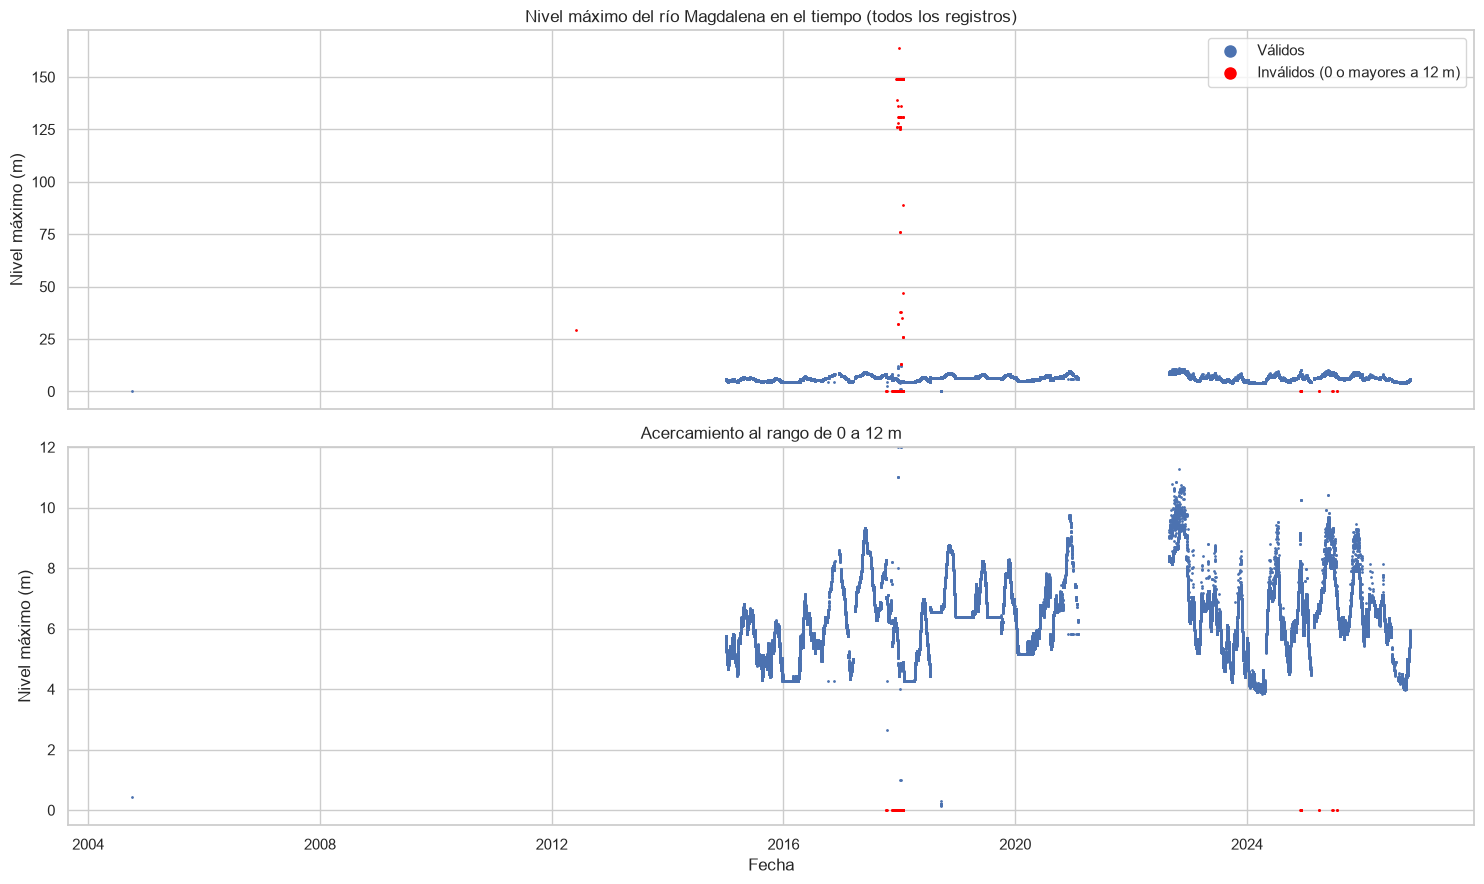

In [20]:
limite = 12
invalidos = (df_unico["ValorObservado"] == 0) | (df_unico["ValorObservado"] > limite)
validos = df_unico[~invalidos]
anomalos = df_unico[invalidos]

fig, ejes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

ejes[0].scatter(validos["FechaObservacion"], validos["ValorObservado"], s=1, label="Válidos")
ejes[0].scatter(anomalos["FechaObservacion"], anomalos["ValorObservado"], s=1, color="red", label="Inválidos (0 o mayores a 12 m)")
ejes[0].set_title("Nivel máximo del río Magdalena en el tiempo (todos los registros)")
ejes[0].set_ylabel("Nivel máximo (m)")
ejes[0].legend(markerscale=8)

ejes[1].scatter(validos["FechaObservacion"], validos["ValorObservado"], s=1)
ejes[1].scatter(anomalos["FechaObservacion"], anomalos["ValorObservado"], s=1, color="red")
ejes[1].set_ylim(-0.5, 12)
ejes[1].set_title("Acercamiento al rango de 0 a 12 m")
ejes[1].set_xlabel("Fecha")
ejes[1].set_ylabel("Nivel máximo (m)")

plt.tight_layout()
plt.show()

In [21]:
fechas_validas = validos["FechaObservacion"]

huecos = pd.DataFrame({
    "desde": fechas_validas.shift(1),
    "hasta": fechas_validas,
    "duracion": fechas_validas.diff()
})
huecos = huecos[huecos["duracion"] > pd.Timedelta(days=30)].sort_values("duracion", ascending=False)

display(huecos)

,desde,hasta,duracion
2,2004-10-04 22:54:03,2015-01-01 00:01:00,3740 days 01:06:57
60101,2021-02-02 11:01:00,2022-08-26 21:22:00,570 days 10:21:00
